In [1]:
import random

import numpy as np

from mdpforge import Benchmark

DISCOUNT = 0.9
SIZE = "small"
PRECISION = 1e-3
REPEATS = 3
SEED = 0

TIMEOUT = 5  # Secondes par essai ; None désactive l'isolation en processus.

np.random.seed(SEED)
random.seed(SEED)

In [ ]:
bench = Benchmark()
bench.reset()
for evaluation_precision in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]:
    for max_iter in [10, 50, 100]:
        bench.add_solver(
            "mdpforge_mpi",
            evaluation_precision=evaluation_precision,
            max_evaluation_iterations=max_iter,
        )
bench.add_all_mdps(size=SIZE)
results = bench.run(
    discount=DISCOUNT,
    precision=PRECISION,
    repeats=REPEATS,
    seed=SEED,
    timeout=TIMEOUT,
)
results.plot_performance_profile(max_factor=20)
results.to_dataframe

C:\Users\orsof\AppData\Local\Temp\ipykernel_14928\1221870479.py:10: UserWarning: Skipping model 'qvbs_consensus': missing dependency 'stormpy'
  bench.add_all_mdps(size=SIZE)
C:\Users\orsof\AppData\Local\Temp\ipykernel_14928\1221870479.py:10: UserWarning: Skipping model 'qvbs_csma': missing dependency 'stormpy'
  bench.add_all_mdps(size=SIZE)
C:\Users\orsof\AppData\Local\Temp\ipykernel_14928\1221870479.py:10: UserWarning: Skipping model 'qvbs_eajs': missing dependency 'stormpy'
  bench.add_all_mdps(size=SIZE)
C:\Users\orsof\AppData\Local\Temp\ipykernel_14928\1221870479.py:10: UserWarning: Skipping model 'qvbs_firewire': missing dependency 'stormpy'
  bench.add_all_mdps(size=SIZE)
C:\Users\orsof\AppData\Local\Temp\ipykernel_14928\1221870479.py:10: UserWarning: Skipping model 'qvbs_firewire_abst': missing dependency 'stormpy'
  bench.add_all_mdps(size=SIZE)
C:\Users\orsof\AppData\Local\Temp\ipykernel_14928\1221870479.py:10: UserWarning: Skipping model 'qvbs_resource_gathering': missing d

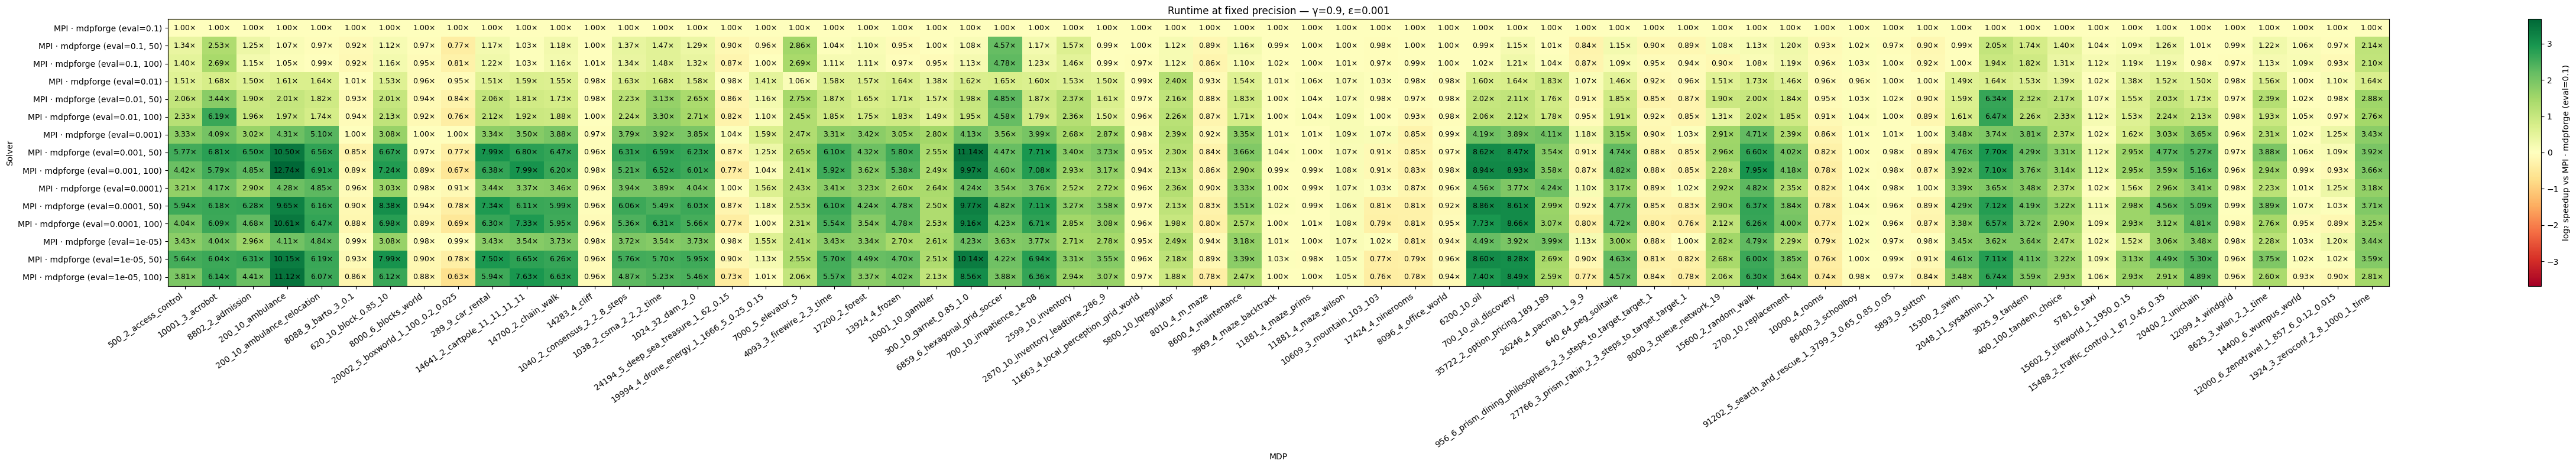

(<Figure size 5000x800 with 2 Axes>,
 <Axes: title={'center': 'Runtime at fixed precision — γ=0.9, ε=0.001'}, xlabel='MDP', ylabel='Solver'>)

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(50, 8))
results.plot_heat(ax=ax)

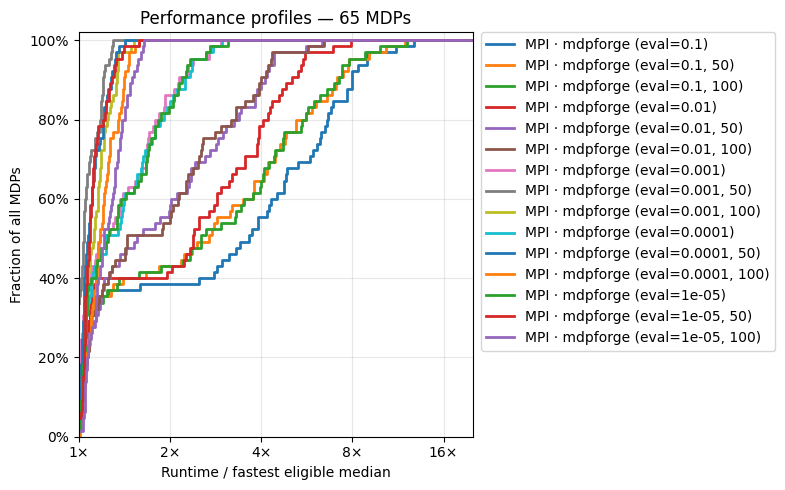

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Performance profiles — 65 MDPs'}, xlabel='Runtime / fastest eligible median', ylabel='Fraction of all MDPs'>)

In [6]:
results.summary()

,model,solver,n_success,n_trials,median_runtime,complete
0,500_2_access_control,mdpforge_mpi_0.1_1,3,3,0.083494,True
1,500_2_access_control,mdpforge_mpi_0.1_50_1,3,3,0.062385,True
2,500_2_access_control,mdpforge_mpi_0.1_100_1,3,3,0.059471,True
3,500_2_access_control,mdpforge_mpi_0.01_1,3,3,0.055188,True
4,500_2_access_control,mdpforge_mpi_0.01_50_1,3,3,0.040507,True
...,...,...,...,...,...,...
970,1924_3_zeroconf_2_8_1000_1_time,mdpforge_mpi_0.0001_50_1,3,3,0.005020,True
971,1924_3_zeroconf_2_8_1000_1_time,mdpforge_mpi_0.0001_100_1,3,3,0.005731,True
972,1924_3_zeroconf_2_8_1000_1_time,mdpforge_mpi_1e-05_1,3,3,0.005418,True
973,1924_3_zeroconf_2_8_1000_1_time,mdpforge_mpi_1e-05_50_1,3,3,0.005191,True


In [7]:
results.export_csv()

WindowsPath('c:/Users/orsof/github/mdpforge/notebooks/artifacts/benchmark/bench_2026-10-28_11-46-52_267574.csv')